# SO SÁNH YOLOv11 VỚI CÁC MÔ HÌNH YOLO THẾ HỆ TRƯỚC

Huấn luyện thêm 3 mô hình trên **cùng bộ dataset** của hệ thống giám sát (`dataset/data.yaml`, 9 lớp) rồi so sánh với mô hình YOLOv11n đã huấn luyện ở file *code chương trình nhận diện*:

| Mô hình | Năm | Trọng số gốc (pretrained COCO) | Kết quả huấn luyện |
|---|---|---|---|
| YOLOv3-tiny | 2018 | `yolov3-tinyu.pt` | `runs/detect/so_sanh/1_YOLOv3-tiny/train` |
| YOLOv5n | 2020 | `yolov5nu.pt` | `runs/detect/so_sanh/2_YOLOv5n/train` |
| YOLOv8n | 2023 | `yolov8n.pt` | `runs/detect/so_sanh/3_YOLOv8n/train` |
| **YOLOv11n** | 2024 | `yolo11n.pt` | `runs/detect/train` *(đã có, không train lại)* |

**Thư mục kết quả** `runs/detect/so_sanh/`: mỗi mô hình một thư mục (`1_YOLOv3-tiny`, `2_YOLOv5n`, `3_YOLOv8n`, `4_YOLOv11n`). Trong đó `train/` là kết quả huấn luyện, `danh_gia_val/` và `danh_gia_test/` là kết quả đánh giá (ma trận nhầm lẫn, đường cong PR, ...). Bảng và biểu đồ so sánh 4 mô hình nằm ở `5_tong_hop/`.

**So sánh công bằng:** 3 mô hình mới dùng đúng lệnh huấn luyện của YOLOv11n (cùng 50 epoch, ảnh 640, các siêu tham số còn lại để mặc định). Cả 4 mô hình được đánh giá trên cùng tập validation/test và đo tốc độ trên cùng máy.

**Quy trình:** huấn luyện 3 mô hình → đánh giá 4 mô hình → đo độ phức tạp và tốc độ → bảng so sánh → biểu đồ → kết luận.

## 0. Cấu hình

In [1]:
import sys
from pathlib import Path
import time
import warnings
warnings.filterwarnings("ignore")

import yaml
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO
from ultralytics.utils.torch_utils import get_flops

PROJECT_DIR = Path.cwd()
DATASET_DIR = PROJECT_DIR / "dataset"                 # thư mục chứa dataset (ảnh và tệp cấu hình data.yaml)
DATA_YAML = DATASET_DIR / "data.yaml"                 # tệp cấu hình dataset (dùng để train)
TEST_IMAGES = DATASET_DIR / "test" / "images"         # ảnh dùng để đo tốc độ
RUNS_DIR = PROJECT_DIR / "runs" / "detect"
SO_SANH_DIR = RUNS_DIR / "so_sanh"                    # mọi kết quả so sánh, mỗi mô hình một thư mục
TONG_HOP_DIR = SO_SANH_DIR / "5_tong_hop"             # bảng và biểu đồ so sánh 4 mô hình
TONG_HOP_DIR.mkdir(parents=True, exist_ok=True)

# Giống lệnh train YOLOv11n ở notebook chính
EPOCHS = 50
IMGSZ = 640
DEVICE = "0"
# Số tiến trình nạp ảnh. Mặc định 8 (val dùng gấp đôi = 16) làm máy hết RAM ở lần chạy trước.
# Chỉ ảnh hưởng tốc độ nạp ảnh, không ảnh hưởng độ chính xác. Nếu vẫn báo "Insufficient memory" thì giảm còn 1 hoặc 0.
WORKERS = 2

# Tên mô hình -> thư mục kết quả (train/, danh_gia_val/, danh_gia_test/)
THU_MUC = {
    "YOLOv3-tiny": SO_SANH_DIR / "1_YOLOv3-tiny",
    "YOLOv5n": SO_SANH_DIR / "2_YOLOv5n",
    "YOLOv8n": SO_SANH_DIR / "3_YOLOv8n",
    "YOLOv11n": SO_SANH_DIR / "4_YOLOv11n",
}
# YOLOv11n là mô hình của hệ thống: train ở notebook chính, giao diện và bản web đọc trọng số ở runs/detect/train
THU_MUC_TRAIN = {ten: thu_muc / "train" for ten, thu_muc in THU_MUC.items()}
THU_MUC_TRAIN["YOLOv11n"] = RUNS_DIR / "train"
MO_HINH = {ten: thu_muc / "weights" / "best.pt" for ten, thu_muc in THU_MUC_TRAIN.items()}
MO_HINH_CHINH = "YOLOv11n"
PPE_CLASSES = {"Helmet", "Gloves", "Safety Vest", "Safety Boot"}   # 4 trang bị bắt buộc


def da_train_xong(ten):
    """True nếu mô hình đã có best.pt và đã train đủ EPOCHS epoch (không bị ngắt giữa chừng)."""
    results_csv = THU_MUC_TRAIN[ten] / "results.csv"
    return MO_HINH[ten].exists() and results_csv.exists() and len(pd.read_csv(results_csv)) >= EPOCHS


def huan_luyen(ten, trong_so_goc, retrain=False):
    """Train một mô hình với đúng lệnh train của YOLOv11n. Nếu lần trước bị ngắt giữa chừng thì train tiếp từ last.pt."""
    if da_train_xong(ten) and not retrain:
        print(f"Đã có trọng số {ten}, bỏ qua bước train: {MO_HINH[ten]}")
        return
    last = MO_HINH[ten].with_name("last.pt")
    if last.exists() and not retrain:
        print(f"{ten}: lần train trước bị ngắt, train tiếp từ {last}")
        YOLO(str(last)).train(resume=True, workers=WORKERS)
    else:
        model = YOLO(trong_so_goc)               # trọng số gốc (pretrained COCO), tự tải về nếu chưa có
        model.train(
            data=str(DATA_YAML),
            task="detect",
            imgsz=IMGSZ,
            epochs=EPOCHS,
            project=str(THU_MUC[ten]),
            name="train",
            exist_ok=True,
            device=DEVICE,
            workers=WORKERS,
        )
    print(f"Best weights: {MO_HINH[ten]}")


print(f"Python: {sys.executable}")
if ".venv" not in sys.executable:
    print("CHÚ Ý: kernel không phải .venv của project, hãy chọn lại kernel .venv (góc trên bên phải).")
print(f"Project: {PROJECT_DIR}")
print(f"Dataset config: {DATA_YAML}")
print(f"Kết quả so sánh: {SO_SANH_DIR}")

Python: C:\A_Nam4\Học Máy\Nhóm 1\YOLOv11_Project\.venv\Scripts\python.exe
Project: C:\A_Nam4\Học Máy\Nhóm 1\YOLOv11_Project
Dataset config: C:\A_Nam4\Học Máy\Nhóm 1\YOLOv11_Project\dataset\data.yaml
Kết quả so sánh: C:\A_Nam4\Học Máy\Nhóm 1\YOLOv11_Project\runs\detect\so_sanh


In [2]:
import ultralytics
print(f"Ultralytics: {ultralytics.__version__}")
# kiểm tra các tệp và thư mục quan trọng
required_paths = [
    DATA_YAML,
    DATASET_DIR / "train" / "images",
    DATASET_DIR / "valid" / "images",
    DATASET_DIR / "test" / "images",
    MO_HINH[MO_HINH_CHINH],
]
for path in required_paths:
    print(f"{'OK' if path.exists() else 'MISSING'}: {path}")

# kiểm tra 3 mô hình mới được train cùng điều kiện với YOLOv11n
args_v11 = yaml.safe_load((RUNS_DIR / "train" / "args.yaml").read_text(encoding="utf-8"))
print(f"\nYOLOv11n đã train với: epochs = {args_v11['epochs']}, imgsz = {args_v11['imgsz']}, "
      f"batch = {args_v11['batch']}, optimizer = {args_v11['optimizer']}")
if (args_v11["epochs"], args_v11["imgsz"]) != (EPOCHS, IMGSZ):
    print("CHÚ Ý: EPOCHS/IMGSZ ở cell cấu hình khác lần train YOLOv11n, hãy sửa lại cho giống.")

Ultralytics: 8.4.163
OK: C:\A_Nam4\Học Máy\Nhóm 1\YOLOv11_Project\dataset\data.yaml
OK: C:\A_Nam4\Học Máy\Nhóm 1\YOLOv11_Project\dataset\train\images
OK: C:\A_Nam4\Học Máy\Nhóm 1\YOLOv11_Project\dataset\valid\images
OK: C:\A_Nam4\Học Máy\Nhóm 1\YOLOv11_Project\dataset\test\images
OK: C:\A_Nam4\Học Máy\Nhóm 1\YOLOv11_Project\runs\detect\train\weights\best.pt

YOLOv11n đã train với: epochs = 50, imgsz = 640, batch = 16, optimizer = auto


## 1. Huấn luyện YOLOv3-tiny

Bản rút gọn của YOLOv3 (2018): backbone Darknet nông, chỉ 2 đầu ra nên dễ bỏ sót vật nhỏ như găng tay, giày.

Mặc định bỏ qua nếu đã train xong. Đặt `RETRAIN_V3 = True` để huấn luyện lại (khoảng 1,5 giờ trên RTX 3050). Nếu lần train trước bị ngắt giữa chừng, cell sẽ tự train tiếp từ `last.pt` (chạy lại cell là được).

In [3]:
RETRAIN_V3 = False

huan_luyen("YOLOv3-tiny", "yolov3-tinyu.pt", retrain=RETRAIN_V3)

Đã có trọng số YOLOv3-tiny, bỏ qua bước train: C:\A_Nam4\Học Máy\Nhóm 1\YOLOv11_Project\runs\detect\so_sanh\1_YOLOv3-tiny\train\weights\best.pt


## 2. Huấn luyện YOLOv5n

Bản nano của YOLOv5 (2020): backbone CSPDarknet với khối C3. Dùng bản `u` của Ultralytics (đầu ra anchor-free) để train cùng một thư viện.

Mặc định bỏ qua nếu đã train xong. Đặt `RETRAIN_V5 = True` để huấn luyện lại (khoảng 1,5 giờ trên RTX 3050). Nếu lần train trước bị ngắt giữa chừng, cell sẽ tự train tiếp từ `last.pt` (chạy lại cell là được).

In [4]:
RETRAIN_V5 = False

huan_luyen("YOLOv5n", "yolov5nu.pt", retrain=RETRAIN_V5)

Đã có trọng số YOLOv5n, bỏ qua bước train: C:\A_Nam4\Học Máy\Nhóm 1\YOLOv11_Project\runs\detect\so_sanh\2_YOLOv5n\train\weights\best.pt


## 3. Huấn luyện YOLOv8n

Bản nano của YOLOv8 (2023), thế hệ liền trước YOLO11: khối C2f, đầu ra anchor-free tách riêng phân loại và định vị.

Mặc định bỏ qua nếu đã train xong. Đặt `RETRAIN_V8 = True` để huấn luyện lại (khoảng 1,5 giờ trên RTX 3050). Nếu lần train trước bị ngắt giữa chừng, cell sẽ tự train tiếp từ `last.pt` (chạy lại cell là được).

In [5]:
RETRAIN_V8 = False

huan_luyen("YOLOv8n", "yolov8n.pt", retrain=RETRAIN_V8)

Đã có trọng số YOLOv8n, bỏ qua bước train: C:\A_Nam4\Học Máy\Nhóm 1\YOLOv11_Project\runs\detect\so_sanh\3_YOLOv8n\train\weights\best.pt


## 4. Đánh giá 4 mô hình trên tập validation và test

Kết quả chi tiết của từng mô hình (ma trận nhầm lẫn, đường cong PR, ...) được lưu trong `runs/detect/so_sanh/<mô hình>/danh_gia_val` và `danh_gia_test`.

In [6]:
ket_qua, theo_lop = [], []

for ten, best in MO_HINH.items():
    if not best.exists():
        print(f"\n##### {ten}: chưa có {best}, bỏ qua (hãy chạy cell huấn luyện)")
        continue
    eval_model = YOLO(str(best))
    print(f"\n##### {ten}")
    for split in ("val", "test"):
        metrics = eval_model.val(
            data=str(DATA_YAML),
            split=split,
            imgsz=IMGSZ,
            device=DEVICE,
            workers=WORKERS,
            project=str(THU_MUC[ten]),
            name=f"danh_gia_{split}",
            exist_ok=True,
            verbose=False,
        )
        box = metrics.box
        ket_qua.append({"Mô hình": ten, "Tập": split, "Precision": box.mp, "Recall": box.mr,
                        "mAP50": box.map50, "mAP50-95": box.map})
        print(f"=== Tập {split}: P = {box.mp:.3f}, R = {box.mr:.3f}, "
              f"mAP50 = {box.map50:.3f}, mAP50-95 = {box.map:.3f}")
        print(f"    {'Lớp':<13}{'P':>7}{'R':>7}{'mAP50':>8}{'mAP50-95':>10}")
        for i, class_id in enumerate(box.ap_class_index):
            name = eval_model.names[int(class_id)]
            theo_lop.append({"Mô hình": ten, "Tập": split, "Lớp": name,
                             "mAP50": box.ap50[i], "mAP50-95": box.ap[i]})
            mark = "  <- trang bị bắt buộc" if name in PPE_CLASSES else ""
            print(f"    {name:<13}{box.p[i]:>7.3f}{box.r[i]:>7.3f}"
                  f"{box.ap50[i]:>8.3f}{box.ap[i]:>10.3f}{mark}")


##### YOLOv3-tiny


Ultralytics 8.4.163  Python-3.11.9 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)


YOLOv3-tiny summary (fused): 34 layers, 12,132,290 parameters, 0 gradients, 18.9 GFLOPs


val: Fast image access  (ping: 0.00.0 ms, read: 386.4156.3 MB/s, size: 66.1 KB)


val: Scanning C:\A_Nam4\Học Máy\Nhóm 1\YOLOv11_Project\dataset\valid\labels.cache... 1584 images, 32 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1584/1584  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 1% ──────────── 1/99 16.2s/it 4.9s<26:30

... (662 outputs left out)

                   all        858       8248      0.834       0.78      0.813      0.435


Speed: 1.3ms preprocess, 5.6ms inference, 0.0ms loss, 1.9ms postprocess per image


Results saved to C:\A_Nam4\Hc My\Nhm 1\YOLOv11_Project\runs\detect\so_sanh\4_YOLOv11n\danh_gia_test


=== Tập test: P = 0.834, R = 0.780, mAP50 = 0.813, mAP50-95 = 0.435
    Lớp                P      R   mAP50  mAP50-95
    Gloves         0.775  0.688   0.705     0.331  <- trang bị bắt buộc
    Helmet         0.938  0.918   0.937     0.549  <- trang bị bắt buộc
    Person         0.922  0.919   0.936     0.622
    Safety Boot    0.771  0.693   0.737     0.336  <- trang bị bắt buộc
    Safety Vest    0.866  0.899   0.908     0.559  <- trang bị bắt buộc
    bare-arms      0.794  0.681   0.710     0.289
    no-boot        0.813  0.665   0.795     0.449
    no-helmet      0.822  0.734   0.751     0.316
    no-vest        0.806  0.819   0.839     0.463


## 5. Độ phức tạp và tốc độ

- **Số tham số** và **GFLOPs**: mô hình càng nhỏ càng dễ chạy trên máy yếu, camera công trường.
- **Tốc độ**: thời gian xử lý **một ảnh** (tiền xử lý + suy luận + hậu xử lý), trung bình trên `SO_ANH_DO_TOC_DO` ảnh test, giống cách hệ thống giám sát chạy trên từng khung hình video/camera.
- **Thời gian train**: lấy từ `results.csv` của từng mô hình.

In [7]:
SO_ANH_DO_TOC_DO = 200
KHOI_DONG = 10                                        # vài ảnh đầu để GPU khởi động, không tính
anh_test = sorted(TEST_IMAGES.iterdir())[:SO_ANH_DO_TOC_DO + KHOI_DONG]

phuc_tap = []
for ten, best in MO_HINH.items():
    if not best.exists():
        continue
    model = YOLO(str(best))
    so_tham_so = sum(p.numel() for p in model.model.parameters())
    gflops = get_flops(model.model, imgsz=IMGSZ)

    thoi_gian = []
    for i, path in enumerate(anh_test):
        speed = model.predict(source=str(path), imgsz=IMGSZ, device=DEVICE, verbose=False)[0].speed
        if i >= KHOI_DONG:
            thoi_gian.append(sum(speed.values()))
    ms = sum(thoi_gian) / len(thoi_gian)

    results_csv = pd.read_csv(THU_MUC_TRAIN[ten] / "results.csv")
    results_csv.columns = results_csv.columns.str.strip()
    # cột time đếm lại từ 0 khi train tiếp từ last.pt, nên cộng thời gian cuối của từng lần chạy
    cot_time = results_csv["time"]
    phut_train = cot_time[cot_time.shift(-1, fill_value=0) < cot_time].sum() / 60

    phuc_tap.append({"Mô hình": ten, "Tham số (triệu)": so_tham_so / 1e6, "GFLOPs": gflops,
                     "ms/ảnh": ms, "FPS": 1000 / ms, "Train (phút)": phut_train})
    print(f"{ten:<12} {so_tham_so / 1e6:5.2f}M tham số | {gflops:5.1f} GFLOPs | "
          f"{ms:5.1f} ms/ảnh (~{1000 / ms:.0f} FPS) | train {phut_train:.0f} phút")

YOLOv3-tiny  12.14M tham số |  19.1 GFLOPs |  18.3 ms/ảnh (~55 FPS) | train 79 phút


YOLOv5n       2.51M tham số |   7.2 GFLOPs |  14.9 ms/ảnh (~67 FPS) | train 65 phút


YOLOv8n       3.01M tham số |   8.2 GFLOPs |  12.3 ms/ảnh (~81 FPS) | train 64 phút


YOLOv11n      2.59M tham số |   6.5 GFLOPs |  15.3 ms/ảnh (~65 FPS) | train 98 phút


## 6. Bảng so sánh

Ô tô màu là giá trị tốt nhất của mỗi cột (độ chính xác và FPS: cao hơn là tốt hơn; tham số, GFLOPs, ms/ảnh, thời gian train: thấp hơn là tốt hơn). Bảng được lưu vào `runs/detect/so_sanh/5_tong_hop/bang_so_sanh.csv` và `bang_so_sanh_theo_lop.csv` (mở được bằng Excel).

In [8]:
bang = pd.DataFrame(ket_qua).merge(pd.DataFrame(phuc_tap), on="Mô hình")
bang_lop = pd.DataFrame(theo_lop)
bang.to_csv(TONG_HOP_DIR / "bang_so_sanh.csv", index=False, encoding="utf-8-sig")
bang_lop.to_csv(TONG_HOP_DIR / "bang_so_sanh_theo_lop.csv", index=False, encoding="utf-8-sig")
co_ket_qua = [ten for ten in MO_HINH if ten in set(bang["Mô hình"])]   # các mô hình đã có kết quả

CAO_LA_TOT = ["Precision", "Recall", "mAP50", "mAP50-95", "FPS"]
THAP_LA_TOT = ["Tham số (triệu)", "GFLOPs", "ms/ảnh", "Train (phút)"]
DINH_DANG = {"Precision": "{:.3f}", "Recall": "{:.3f}", "mAP50": "{:.3f}", "mAP50-95": "{:.3f}",
             "Tham số (triệu)": "{:.2f}", "GFLOPs": "{:.1f}", "ms/ảnh": "{:.1f}", "FPS": "{:.0f}",
             "Train (phút)": "{:.0f}"}
TO_MAU = "font-weight: bold; background-color: #fde3d6"

for split in ("test", "val"):
    df = bang[bang["Tập"] == split].drop(columns="Tập").set_index("Mô hình")
    display(df.style.format(DINH_DANG)
            .highlight_max(subset=CAO_LA_TOT, props=TO_MAU)
            .highlight_min(subset=THAP_LA_TOT, props=TO_MAU)
            .set_caption(f"Tập {split}"))

,Precision,Recall,mAP50,mAP50-95,Tham số (triệu),GFLOPs,ms/ảnh,FPS,Train (phút)
Mô hình,,,,,,,,,
YOLOv3-tiny,0.848,0.722,0.765,0.398,12.14,19.1,18.3,55,79
YOLOv5n,0.832,0.755,0.797,0.421,2.51,7.2,14.9,67,65
YOLOv8n,0.839,0.767,0.806,0.432,3.01,8.2,12.3,81,64
YOLOv11n,0.834,0.780,0.813,0.435,2.59,6.5,15.3,65,98


,Precision,Recall,mAP50,mAP50-95,Tham số (triệu),GFLOPs,ms/ảnh,FPS,Train (phút)
Mô hình,,,,,,,,,
YOLOv3-tiny,0.835,0.762,0.789,0.424,12.14,19.1,18.3,55,79
YOLOv5n,0.834,0.791,0.826,0.456,2.51,7.2,14.9,67,65
YOLOv8n,0.847,0.801,0.837,0.469,3.01,8.2,12.3,81,64
YOLOv11n,0.844,0.802,0.832,0.469,2.59,6.5,15.3,65,98


In [9]:
# mAP50 từng lớp trên tập test: hàng là lớp, cột là mô hình
display(bang_lop[bang_lop["Tập"] == "test"]
        .pivot(index="Lớp", columns="Mô hình", values="mAP50")[co_ket_qua]
        .style.format("{:.3f}").highlight_max(axis=1, props=TO_MAU)
        .set_caption("mAP50 theo lớp, tập test"))

Mô hình,YOLOv3-tiny,YOLOv5n,YOLOv8n,YOLOv11n
Lớp,,,,
Gloves,0.654,0.690,0.718,0.705
Helmet,0.906,0.934,0.934,0.937
Person,0.918,0.933,0.939,0.936
Safety Boot,0.664,0.722,0.753,0.737
Safety Vest,0.894,0.908,0.914,0.908
bare-arms,0.615,0.710,0.720,0.710
no-boot,0.725,0.692,0.699,0.795
no-helmet,0.707,0.733,0.706,0.751
no-vest,0.805,0.852,0.869,0.839


## 7. Biểu đồ so sánh

Mỗi mô hình giữ một màu cố định trong mọi biểu đồ. Ảnh được lưu trong `runs/detect/so_sanh/5_tong_hop/`.

In [10]:
MAU_MO_HINH = dict(zip(MO_HINH, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
NEN, CHU, CHU_PHU, LUOI = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": NEN, "axes.facecolor": NEN, "savefig.facecolor": NEN,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "axes.edgecolor": LUOI, "axes.labelcolor": CHU_PHU, "axes.titlecolor": CHU,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": CHU_PHU, "ytick.color": CHU_PHU, "ytick.major.size": 0, "text.color": CHU,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": LUOI, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})


def cot_nhom(ax, df, nhom, thu_tu, cot_gia_tri, nhan_so=True):
    """Cột nhóm: mỗi nhóm trên trục x, trong nhóm mỗi mô hình một cột với màu cố định."""
    rong = 0.8 / len(co_ket_qua)
    for j, ten in enumerate(co_ket_qua):
        y = df[df["Mô hình"] == ten].set_index(nhom)[cot_gia_tri].reindex(thu_tu)
        x = [i + (j - (len(co_ket_qua) - 1) / 2) * rong for i in range(len(thu_tu))]
        cot = ax.bar(x, y, rong, color=MAU_MO_HINH[ten], edgecolor=NEN, linewidth=1.5, label=ten)
        if nhan_so:
            ax.bar_label(cot, fmt="%.3f", padding=2, fontsize=7.5, color=CHU_PHU)
    ax.set_xticks(range(len(thu_tu)), thu_tu)
    ax.tick_params(axis="x", length=0)
    ax.legend(ncols=len(co_ket_qua), loc="upper left", bbox_to_anchor=(0, -0.08))

### 7.1 Độ chính xác trên tập test

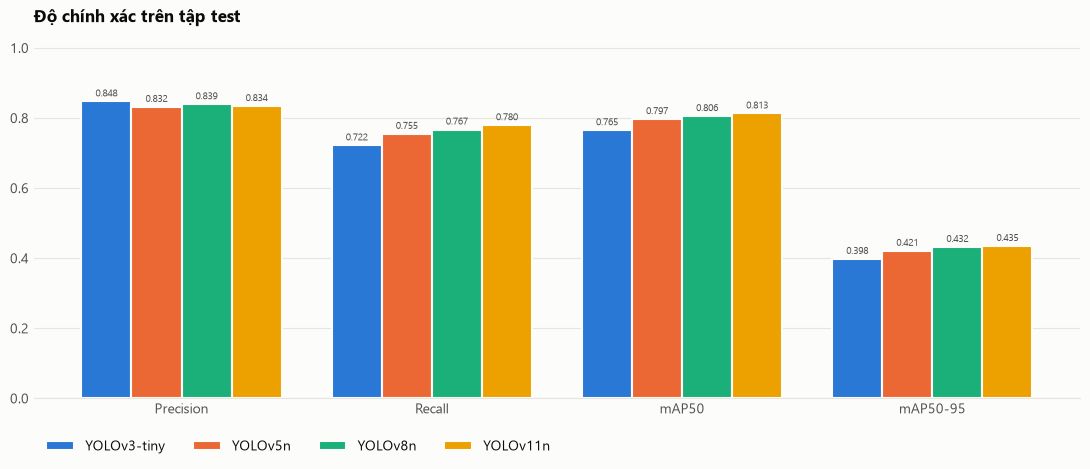

In [11]:
chi_so = ["Precision", "Recall", "mAP50", "mAP50-95"]
dai = bang[bang["Tập"] == "test"].melt(id_vars="Mô hình", value_vars=chi_so,
                                       var_name="Chỉ số", value_name="Giá trị")
fig, ax = plt.subplots(figsize=(11, 4.8))
cot_nhom(ax, dai, "Chỉ số", chi_so, "Giá trị")
ax.set_ylim(0, 1.05)
ax.set_title("Độ chính xác trên tập test")
fig.tight_layout()
fig.savefig(TONG_HOP_DIR / "chi_so_tap_test.png", dpi=150)
plt.show()

### 7.2 mAP50 theo từng lớp trên tập test

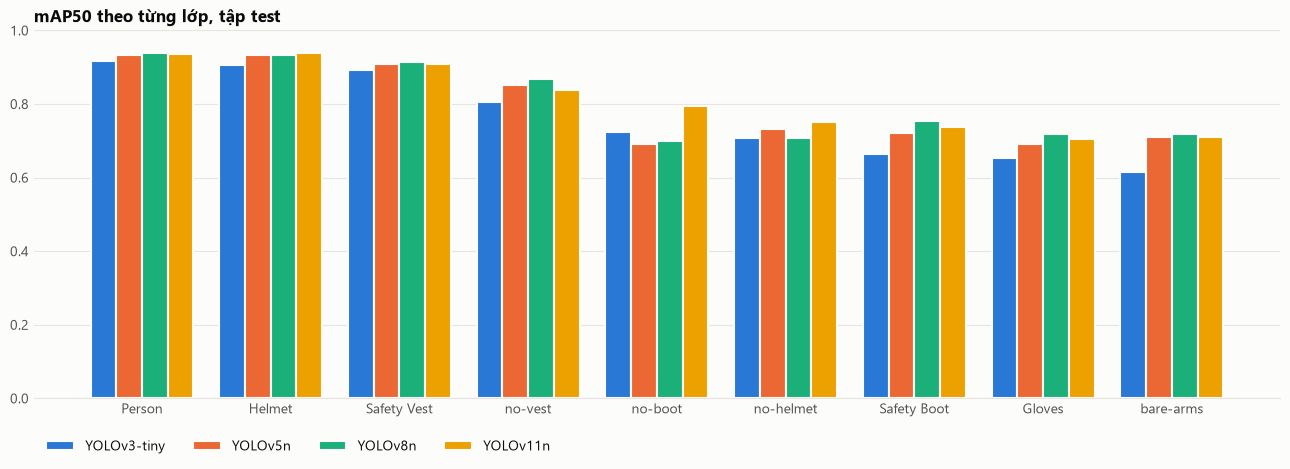

In [12]:
lop = bang_lop[bang_lop["Tập"] == "test"]
thu_tu_lop = list(lop.groupby("Lớp")["mAP50"].mean().sort_values(ascending=False).index)
fig, ax = plt.subplots(figsize=(13, 4.8))
cot_nhom(ax, lop, "Lớp", thu_tu_lop, "mAP50", nhan_so=False)
ax.set_ylim(0, 1)
ax.set_title("mAP50 theo từng lớp, tập test")
fig.tight_layout()
fig.savefig(TONG_HOP_DIR / "map50_theo_lop.png", dpi=150)
plt.show()

### 7.3 Quá trình huấn luyện (mAP50-95 trên tập validation sau mỗi epoch)

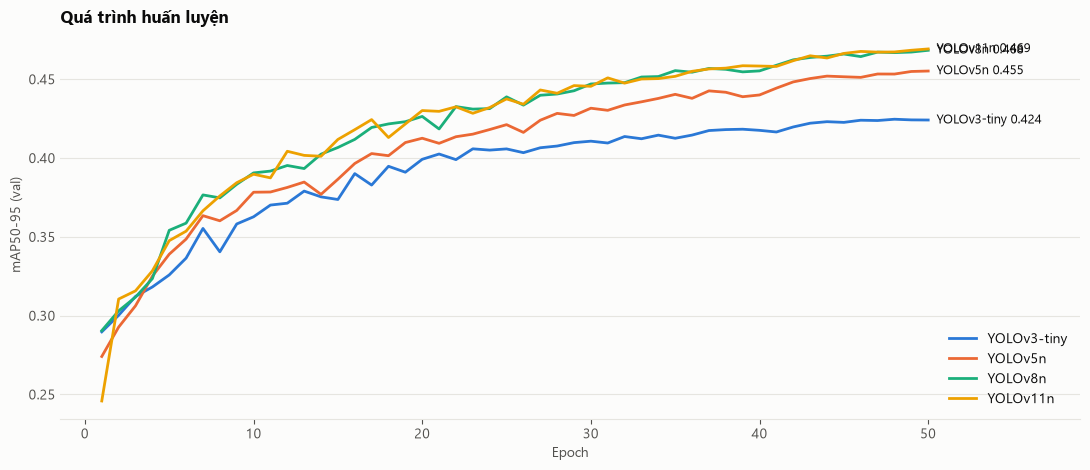

In [13]:
fig, ax = plt.subplots(figsize=(11, 4.8))
for ten in co_ket_qua:
    df = pd.read_csv(THU_MUC_TRAIN[ten] / "results.csv")
    df.columns = df.columns.str.strip()
    y = df["metrics/mAP50-95(B)"]
    ax.plot(df["epoch"], y, color=MAU_MO_HINH[ten], linewidth=2, label=ten)
    ax.annotate(f"{ten} {y.iloc[-1]:.3f}", (df["epoch"].iloc[-1], y.iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9)
ax.set_xlabel("Epoch")
ax.set_ylabel("mAP50-95 (val)")
ax.set_title("Quá trình huấn luyện")
ax.set_xlim(right=EPOCHS * 1.18)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(TONG_HOP_DIR / "qua_trinh_huan_luyen.png", dpi=150)
plt.show()

### 7.4 Tốc độ và độ chính xác (góc trên bên trái là tốt nhất)

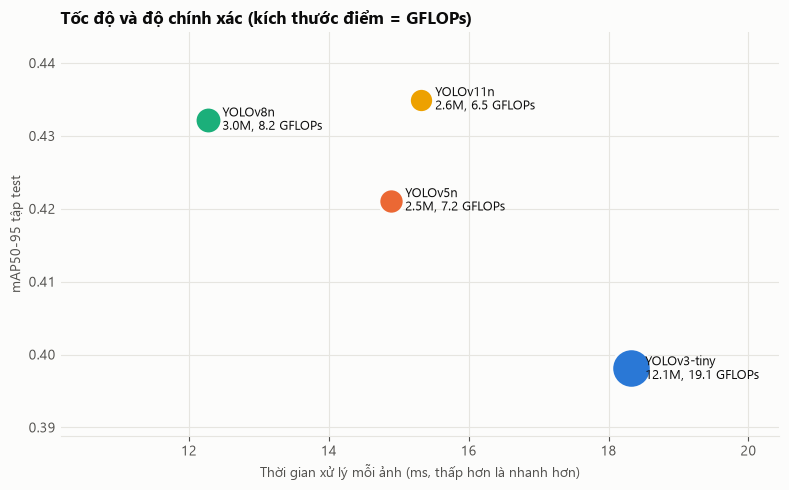

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
for _, dong in bang[bang["Tập"] == "test"].iterrows():
    ax.scatter(dong["ms/ảnh"], dong["mAP50-95"], s=40 + 40 * dong["GFLOPs"],
               color=MAU_MO_HINH[dong["Mô hình"]], edgecolor=NEN, linewidth=2, zorder=3)
    ax.annotate(f"{dong['Mô hình']}\n{dong['Tham số (triệu)']:.1f}M, {dong['GFLOPs']:.1f} GFLOPs",
                (dong["ms/ảnh"], dong["mAP50-95"]), xytext=(10, 0), textcoords="offset points",
                va="center", fontsize=9)
ax.grid(axis="x")
ax.set_xlabel("Thời gian xử lý mỗi ảnh (ms, thấp hơn là nhanh hơn)")
ax.set_ylabel("mAP50-95 tập test")
ax.set_title("Tốc độ và độ chính xác (kích thước điểm = GFLOPs)")
ax.margins(x=0.35, y=0.25)
fig.tight_layout()
fig.savefig(TONG_HOP_DIR / "toc_do_va_do_chinh_xac.png", dpi=150)
plt.show()

## 8. Kết luận

So sánh YOLOv11n với mô hình tốt nhất trong 3 mô hình còn lại ở từng chỉ số. Nếu có chỉ số mà mô hình khác vượt YOLOv11n, cell này ghi rõ để báo cáo trung thực.

In [15]:
for split in ("test", "val"):
    df = bang[bang["Tập"] == split].set_index("Mô hình")
    if MO_HINH_CHINH not in df.index or len(df) < 2:
        print(f"Tập {split}: chưa đủ kết quả để so sánh")
        continue
    print(f"=== Tập {split} ===")
    chinh, khac = df.loc[MO_HINH_CHINH], df.drop(index=MO_HINH_CHINH)
    for cot in CAO_LA_TOT + THAP_LA_TOT:
        doi_thu = khac[cot].idxmax() if cot in CAO_LA_TOT else khac[cot].idxmin()
        chenh = chinh[cot] - khac.loc[doi_thu, cot]
        thang = chenh > 0 if cot in CAO_LA_TOT else chenh < 0
        ket_luan = "YOLOv11n tốt nhất" if thang else ("bằng nhau" if chenh == 0 else f"{doi_thu} tốt hơn")
        print(f"  {cot:<16} YOLOv11n = {chinh[cot]:8.3f} | tốt nhất còn lại: {doi_thu:<12}"
              f"{khac.loc[doi_thu, cot]:8.3f} | chênh {chenh:+.3f} -> {ket_luan}")

=== Tập test ===
  Precision        YOLOv11n =    0.834 | tốt nhất còn lại: YOLOv3-tiny    0.848 | chênh -0.013 -> YOLOv3-tiny tốt hơn
  Recall           YOLOv11n =    0.780 | tốt nhất còn lại: YOLOv8n        0.767 | chênh +0.012 -> YOLOv11n tốt nhất
  mAP50            YOLOv11n =    0.813 | tốt nhất còn lại: YOLOv8n        0.806 | chênh +0.007 -> YOLOv11n tốt nhất
  mAP50-95         YOLOv11n =    0.435 | tốt nhất còn lại: YOLOv8n        0.432 | chênh +0.003 -> YOLOv11n tốt nhất
  FPS              YOLOv11n =   65.264 | tốt nhất còn lại: YOLOv8n       81.435 | chênh -16.171 -> YOLOv8n tốt hơn
  Tham số (triệu)  YOLOv11n =    2.592 | tốt nhất còn lại: YOLOv5n        2.510 | chênh +0.081 -> YOLOv5n tốt hơn
  GFLOPs           YOLOv11n =    6.508 | tốt nhất còn lại: YOLOv5n        7.184 | chênh -0.676 -> YOLOv11n tốt nhất
  ms/ảnh           YOLOv11n =   15.322 | tốt nhất còn lại: YOLOv8n       12.280 | chênh +3.043 -> YOLOv8n tốt hơn
  Train (phút)     YOLOv11n =   97.649 | tốt nhất còn lại: